# Hydrostatics: watch the boat find its floating angle

This standalone notebook walks through the hydrostatic equilibrium calculation.
Run the cells from top to bottom; the tables and plots below are already populated.
Dependencies: Python, NumPy, Matplotlib, and IPython (provided by Jupyter).

This is a visible **Python translation of the original DBB offsets integration,
initial trim search, and coupled draft/trim/heel solve**. It is compared below
against saved results freshly calculated by DBB's unchanged JavaScript core for
both load cases. It is not the earlier exact-STEP/Open CASCADE solver. The Python
walkthrough needs neither Node nor a CAD library to run.

Your coordinate convention throughout:

| Symbol | Meaning | Positive direction |
|---|---|---|
| $x$ | Transverse coordinate | Same as CAD X; port/starboard sign unconfirmed |
| $y$ | Longitudinal coordinate | Forward from the stern |
| $z$ | Height | Upward from the hull baseline |

DBB calls its longitudinal axis **x** and transverse axis **y**. This section swaps
those names back to your convention. The default `updated` CSV is historically
named `front-loaded`, but its edits actually move the battery/payload **aft**.

All tables and plots use full-size **pounds and inches**. Internally the code uses
the same **10× meters / 1000× tonnes** as the DBB project, including its original
finite-difference steps and stopping tolerances. This is static calm-water balance;
it does not add a low-speed or planing model to the propulsion analysis above.

In [3]:
import csv as hs_csv
import hashlib as hs_hashlib
import html as hs_html
import json as hs_json
from pathlib import Path as hs_Path
import numpy as hs_np
import matplotlib.pyplot as hs_plt
from IPython.display import HTML as hs_HTML, display as hs_display

# Edit these, then rerun this notebook from this cell downward.
HS_CASE = "updated"                 # "baseline" or "updated"
HS_WATER_DENSITY_KG_M3 = 1000.0     # nominal freshwater
HS_SCALE = 10.0                    # keep 10 for comparison with original DBB
HS_TRIAL_TRIM_DEG = 0.0            # an angle to inspect before the solved angle
HS_POSITION_OVERRIDES_IN = {}      # optional: {"battery_1": (0.0, 40.0, 4.25)}
# Overrides only affect this run; this notebook never writes your input CSVs.

hs_root = next((p for p in [hs_Path.cwd(), *hs_Path.cwd().parents]
                if (p / "outputs/hydrostatics/hull-offsets-m.csv").is_file()
                and (p / "prop_motor_battery").is_dir()), None)
if hs_root is None:
    raise FileNotFoundError("Run from this repository or its prop_motor_battery folder")
hs_dir = hs_root / "outputs/hydrostatics"
hs_files = {"baseline": "component-masses.csv", "updated": "component-masses-front-loaded.csv"}
if HS_CASE not in hs_files or HS_SCALE <= 0 or HS_WATER_DENSITY_KG_M3 <= 0:
    raise ValueError("Choose baseline/updated and positive scale/water density")
hs_in_to_model_m = 0.0254 * HS_SCALE
hs_lb_to_model_t = 0.00045359237 * HS_SCALE**3
hs_rho = HS_WATER_DENSITY_KG_M3 / 1000  # tonnes per cubic meter

def hs_table(headers, rows):
    def esc(v): return hs_html.escape(str(v))
    head = "".join("<th style='padding:7px;text-align:left'>"+esc(h)+"</th>" for h in headers)
    body = "".join("<tr>"+"".join("<td style='padding:6px;border-top:1px solid #ddd'>"+esc(v)+"</td>" for v in row)+"</tr>" for row in rows)
    hs_display(hs_HTML("<div style='overflow-x:auto'><table><thead><tr>"+head+"</tr></thead><tbody>"+body+"</tbody></table></div>"))

def hs_load_weights(case, overrides=None):
    included, excluded = [], []
    with (hs_dir / hs_files[case]).open(newline="") as stream:
        for row in hs_csv.DictReader(stream):
            if not row["mass_lbs"].strip():
                excluded.append(row["component_id"])
                continue
            mass = float(row["mass_lbs"])
            cg = hs_np.array([float(row[key]) for key in ("cg_x_in", "cg_y_in", "cg_z_in")])
            if overrides and row["component_id"] in overrides:
                cg = hs_np.asarray(overrides[row["component_id"]], dtype=float)
            if cg.shape != (3,) or not hs_np.isfinite([mass, *cg]).all() or mass < 0:
                raise ValueError("Invalid mass or center: "+row["component_id"])
            included.append({"id":row["component_id"], "mass_lbs":mass, "cg_in":cg})
    if not included or sum(c["mass_lbs"] for c in included) <= 0:
        raise ValueError("Positive total mass is required")
    return included, excluded

def hs_mass_properties(components):
    mass_lb = sum(c["mass_lbs"] for c in components)
    cg_in = sum(c["mass_lbs"]*c["cg_in"] for c in components)/mass_lb
    return mass_lb*hs_lb_to_model_t, cg_in*hs_in_to_model_m

hs_components, hs_excluded = hs_load_weights(HS_CASE, HS_POSITION_OVERRIDES_IN)
hs_mass_t, hs_G = hs_mass_properties(hs_components)
hs_target_volume = hs_mass_t / hs_rho
hs_table(["Component", "Mass (lb)", "CG X (in)", "CG Y (in)", "CG Z (in)"],
         [[c["id"], f'{c["mass_lbs"]:.3f}', *[f'{v:.3f}' for v in c["cg_in"]]] for c in hs_components])
print(f"Total: {hs_mass_t/hs_lb_to_model_t:.3f} lb; combined CG X/Y/Z: {hs_G/hs_in_to_model_m} in")
print(f"Required water displacement: {hs_target_volume/HS_SCALE**3/0.028316846592:.6f} ft³")
print(f"{len(hs_excluded)} blank mass rows excluded; frame mass/CG includes the hull.")

Component,Mass (lb),CG X (in),CG Y (in),CG Z (in)
backbone,35.107,0.011,28.751,7.023
battery_1,30.000,0.000,12.932,4.250
motor_port,15.000,-4.000,12.593,3.374
motor_starboard,15.000,4.000,12.593,3.374
payload front,15.000,0.000,12.932,4.250
payload back,15.000,0.000,12.932,4.250


Total: 125.107 lb; combined CG X/Y/Z: [3.08677372e-03 1.72897708e+01 4.81808741e+00] in
Required water displacement: 2.004022 ft³
12 blank mass rows excluded; frame mass/CG includes the hull.


## 1. The three equations we want to satisfy

The combined mass center is known from the weights:

$$\mathbf G = \frac{\sum_i m_i\mathbf r_i}{\sum_i m_i}.$$

We search for the water plane

$$z_w(x,y)=h-k(y-y_m)+p x,\qquad
\theta=\tan^{-1}(k),\quad \phi=\tan^{-1}(p).$$

$h$ is water-plane height at mid-length; $k$ is the stern-down trim slope; $p$ is
the heel slope. Positive $p$ means the positive-X side sits deeper. The boat is
symmetric about X = 0, so the transverse plane reference is zero.

After cutting the cells at that plane, the unknown center of buoyancy is

$$V=\sum_i\Delta V_i,\qquad
\mathbf B=\frac{\sum_i\Delta V_i\mathbf r_{i,\mathrm{wet}}}{V}.$$

DBB adjusts $(h,k,p)$ to drive **all three residuals to zero**:

$$r_V=\frac{V}{m/\rho}-1,$$
$$r_y=(y_B-y_G)-k(z_B-z_G),$$
$$r_x=(x_B-x_G)+p(z_B-z_G).$$

The first equation balances supported mass. The other two align B and G along the
water-plane normal $\mathbf n=(-p,k,1)$, the direction of physical vertical in
boat coordinates. **B and G need not occupy the same point.** Their separation
must be parallel to that normal, making the force couple's torque zero:
$\boldsymbol\tau=(\mathbf B-\mathbf G)\times(mg\hat{\mathbf n})=0$.

In [4]:
# Read the same offset grid used to prepare the DBB projects. No archive dependency.
with (hs_dir / "hull-offsets-m.csv").open(newline="") as hs_stream:
    hs_offset_rows = list(hs_csv.reader(hs_stream))
hs_stations = hs_np.array([float(v) for v in hs_offset_rows[0][1:]]) * HS_SCALE
hs_heights = hs_np.array([float(row[0]) for row in hs_offset_rows[1:]]) * HS_SCALE
hs_half = hs_np.array([[hs_np.nan if v == "" else float(v) for v in row[1:]]
                       for row in hs_offset_rows[1:]]) * HS_SCALE
if hs_half.shape != (len(hs_heights), len(hs_stations)):
    raise ValueError("Offset table shape mismatch")
if not (hs_np.diff(hs_stations) > 0).all() or not (hs_np.diff(hs_heights) > 0).all():
    raise ValueError("Stations/heights must be increasing")
hs_present = ~hs_np.isnan(hs_half)
if not hs_present.any(axis=1).all():
    raise ValueError("DBB requires at least one hull entry at every height")
# Match cleanOffsets: the table reference length ends at its last nonblank station.
# Then scale that reference to the project LOA, as DBB does on import.
hs_geometry_project = hs_dir / "dbb-project-10x.json"
hs_hull_spec = hs_json.loads(hs_geometry_project.read_text())["hulls"][0]
hs_used_stations = hs_np.flatnonzero(hs_present.any(axis=0))
hs_table_start = hs_stations[hs_used_stations[0]]
hs_table_end = hs_stations[hs_used_stations[-1]]
hs_stations = (hs_stations-hs_table_start)*(hs_hull_spec["loa"]*HS_SCALE/10)/(hs_table_end-hs_table_start)
hs_heights *= (hs_hull_spec["depth"]*HS_SCALE/10)/hs_heights[-1]
hs_half *= (hs_hull_spec["beam"]*HS_SCALE/10)/(2*hs_np.nanmax(hs_half))
hs_first = hs_stations[hs_present.argmax(axis=1)]
hs_last = hs_stations[len(hs_stations)-1-hs_present[:, ::-1].argmax(axis=1)]
hs_half_filled = hs_np.nan_to_num(hs_half, nan=0.0)
hs_length, hs_depth = float(hs_hull_spec["loa"]*HS_SCALE/10), float(hs_heights[-1])
hs_beam = 2*float(hs_np.nanmax(hs_half))
hs_mid_y = hs_length/2

def hs_section(z, nu):
    """DBB offsetsXRange + offsetsHalf: interpolate height, then station width."""
    z = float(hs_np.clip(z, hs_heights[0], hs_heights[-1]))
    j = int(hs_np.clip(hs_np.searchsorted(hs_heights, z, side="left")-1, 0, len(hs_heights)-2))
    t = (z-hs_heights[j])/(hs_heights[j+1]-hs_heights[j])
    aft = (1-t)*hs_first[j]+t*hs_first[j+1]
    fore = (1-t)*hs_last[j]+t*hs_last[j+1]
    y = aft+(hs_np.arange(nu)+0.5)/nu*(fore-aft)
    half0 = hs_np.interp(y, hs_stations, hs_half_filled[j])
    half1 = hs_np.interp(y, hs_stations, hs_half_filled[j+1])
    half = hs_np.minimum((1-t)*half0+t*half1, hs_beam/2)
    return y, half, (fore-aft)/nu

def hs_make_cells(nz, nu, nx):
    """Mid-height/longitudinal/transverse cells, in DBB's original loop order."""
    columns = {key:[] for key in ["x", "y", "z0", "dz", "full_volume"]}
    dz = hs_depth/nz
    for j in range(nz):
        y, half, dy = hs_section((j+0.5)*dz, nu)
        dx = 2*half/nx
        x = -half[:,None]+(hs_np.arange(nx)[None,:]+0.5)*dx[:,None]
        columns["x"].extend(x.ravel())
        columns["y"].extend(hs_np.repeat(y,nx))
        columns["z0"].extend(hs_np.full(nu*nx,j*dz))
        columns["dz"].extend(hs_np.full(nu*nx,dz))
        columns["full_volume"].extend(hs_np.repeat(dx*dy*dz,nx))
    return {key:hs_np.array(value) for key,value in columns.items()}

hs_initial_grid = hs_make_cells(40,120,1) # original floatState's initial trim search
hs_grid = hs_make_cells(32,90,14)         # original heelSolve's final integration
print(f"Hull: {hs_length/hs_in_to_model_m:.3f} × {hs_beam/hs_in_to_model_m:.3f} × {hs_depth/hs_in_to_model_m:.3f} in")
print(f"Final solve: {len(hs_grid['x']):,} cells (32 vertical × 90 longitudinal × 14 transverse)")

Hull: 72.000 × 24.904 × 12.000 in
Final solve: 40,320 cells (32 vertical × 90 longitudinal × 14 transverse)


## 2. What each $\Delta V_i$ is

At a cell's sampled X/Y location, cut its vertical height at the water plane:

$$f_i=\operatorname{clip}\left(\frac{z_w(x_i,y_i)-z_{i,0}}{\Delta z_i},0,1\right),
\qquad \Delta V_i=f_i\,\Delta V_{i,\mathrm{full}}.$$

- $f_i=0$: dry cell; $f_i=1$: completely wet; intermediate values: partly wet.
- The submerged portion's center height is
  $z_{i,\mathrm{wet}}=z_{i,0}+f_i\Delta z_i/2$.
- DBB uses the plane at the cell's X/Y center, rather than exactly clipping every
  sloping cell face. This is numerical integration, not an exact CAD intersection.

The displayed B coordinate is therefore volume-weighted over the **wet parts**,
not an average of all hull vertices or just the outline.

In [5]:
def hs_immerse(grid, state):
    h,k,p = state
    water_z = h-k*(grid["y"]-hs_mid_y)+p*grid["x"]
    wet_fraction = hs_np.clip((water_z-grid["z0"])/grid["dz"],0,1)
    wet_volume = grid["full_volume"]*wet_fraction
    volume = float(wet_volume.sum())
    if volume <= 0:
        raise ValueError("Trial plane leaves the entire hull dry")
    wet_z = grid["z0"]+0.5*wet_fraction*grid["dz"]
    B = hs_np.array([hs_np.dot(wet_volume,grid["x"]),
                     hs_np.dot(wet_volume,grid["y"]),
                     hs_np.dot(wet_volume,wet_z)])/volume
    return {"V":volume,"B":B,"fraction":wet_fraction,"dV":wet_volume,"wet_z":wet_z}

def hs_residual(state, mass_t, G, grid):
    wet = hs_immerse(grid,state)
    delta = wet["B"]-G
    _,k,p = state
    residual = hs_np.array([wet["V"]/(mass_t/hs_rho)-1,
                            delta[1]-k*delta[2], delta[0]+p*delta[2]])
    return residual,wet

def hs_settle_height(k,p,target_volume,grid,iterations=28):
    lo = -hs_length*abs(k)-hs_beam*abs(p)
    hi = hs_depth+hs_length*abs(k)+hs_beam*abs(p)
    full_volume = float(grid["full_volume"].sum())
    if target_volume <= 0 or target_volume >= full_volume:
        raise ValueError("Required displacement is outside this hull's modeled capacity")
    for _ in range(iterations):
        mid = (lo+hi)/2
        volume = hs_immerse(grid,[mid,k,p])["V"]
        if volume < target_volume: lo = mid
        else: hi = mid
    return (lo+hi)/2

hs_trial_k = float(hs_np.tan(hs_np.deg2rad(HS_TRIAL_TRIM_DEG)))
hs_trial_h = hs_settle_height(hs_trial_k,0,hs_target_volume,hs_grid)
hs_trial_state = hs_np.array([hs_trial_h,hs_trial_k,0.])
hs_trial_r, hs_trial_wet = hs_residual(hs_trial_state,hs_mass_t,hs_G,hs_grid)
hs_categories = {"Dry":hs_trial_wet["fraction"]==0,
                 "Partly wet":(hs_trial_wet["fraction"]>0)&(hs_trial_wet["fraction"]<1),
                 "Fully wet":hs_trial_wet["fraction"]==1}
hs_sample_indices = [int(i) for mask in hs_categories.values() for i in hs_np.flatnonzero(mask)[:3]]
hs_table(["Cell", "X (in)", "Y (in)", "Bottom Z (in)", "Wet fraction", "Full V (in³)", "Wet ΔV (in³)", "Wet centroid Z (in)"],
         [[i,*[f'{hs_grid[key][i]/hs_in_to_model_m:.3f}' for key in ["x","y","z0"]],
           f'{hs_trial_wet["fraction"][i]:.4f}', f'{hs_grid["full_volume"][i]/hs_in_to_model_m**3:.5f}',
           f'{hs_trial_wet["dV"][i]/hs_in_to_model_m**3:.5f}',
           "dry" if hs_trial_wet["fraction"][i]==0 else f'{hs_trial_wet["wet_z"][i]/hs_in_to_model_m:.3f}'] for i in hs_sample_indices])
print("Trial angle:",HS_TRIAL_TRIM_DEG,"degrees; wet cell counts:",{k:int(v.sum()) for k,v in hs_categories.items()})
print("Trial B X/Y/Z:",hs_trial_wet["B"]/hs_in_to_model_m,"in")
print(f"Supported weight: {hs_trial_wet['V']*hs_rho/hs_lb_to_model_t:.6f} lb")
print(f"Fore/aft alignment error: {hs_trial_r[1]/hs_in_to_model_m:+.6f} in (still unbalanced even though volume is right)")

Cell,X (in),Y (in),Bottom Z (in),Wet fraction,Full V (in³),Wet ΔV (in³),Wet centroid Z (in)
21420,-6.726,0.348,6.375,0.0000,0.27026,0.00000,dry
21421,-5.691,0.348,6.375,0.0000,0.27026,0.00000,dry
21422,-4.656,0.348,6.375,0.0000,0.27026,0.00000,dry
20160,-6.570,0.344,6.000,0.9310,0.26083,0.24282,6.175
20161,-5.559,0.344,6.000,0.9310,0.26083,0.24282,6.175
20162,-4.549,0.344,6.000,0.9310,0.26083,0.24282,6.175
0,-1.167,0.124,0.000,1.0000,0.01675,0.01675,0.188
1,-0.987,0.124,0.000,1.0000,0.01675,0.01675,0.188
2,-0.808,0.124,0.000,1.0000,0.01675,0.01675,0.188


Trial angle: 0.0 degrees; wet cell counts: {'Dry': 18900, 'Partly wet': 1260, 'Fully wet': 20160}
Trial B X/Y/Z: [ 0.         24.03370622  3.88677755] in
Supported weight: 125.107000 lb
Fore/aft alignment error: +6.743935 in (still unbalanced even though volume is right)


## 3. Watch the solver adjust height and angle

DBB first finds an upright draft and a trim-only initial guess using bisection
on a 40×120 grid. That initial guess aligns longitudinal B/G coordinates but does
not yet include their vertical separation. Its final 32×90×14-cell Newton solve
uses all three residual equations above.

At iteration $j$, approximate the Jacobian by small trial changes to each unknown:

$$J_{ab}\simeq\frac{r_a(\mathbf u+\epsilon_b\mathbf e_b)-r_a(\mathbf u)}{\epsilon_b},
\qquad J\Delta\mathbf u=-\mathbf r,\qquad
\mathbf u_{j+1}=\mathbf u_j+\operatorname{clip}(\Delta\mathbf u).$$

Here $\mathbf u=(h,k,p)$. The code below keeps DBB's normal-resolution grid,
iteration counts, finite-difference steps and update limits visible. NumPy's
linear solve replaces its three-by-three Gaussian elimination. It **raises an
error** if the coupled solve does not converge rather than silently reporting a
trim-only fallback as a full equilibrium.

In [6]:
def hs_solve(components):
    mass_t,G = hs_mass_properties(components)
    target = mass_t/hs_rho
    level = hs_settle_height(0,0,target,hs_initial_grid)
    def initial_lcb(k):
        h = hs_settle_height(k,0,target,hs_initial_grid)
        return hs_immerse(hs_initial_grid,[h,k,0])["B"][1]
    low,high = -0.2,0.2
    if not (initial_lcb(high) <= G[1] <= initial_lcb(low)):
        raise ValueError("CG outside DBB's initial trim-search bracket; no fallback assumed")
    for _ in range(30):
        mid = (low+high)/2
        if initial_lcb(mid) > G[1]: low = mid
        else: high = mid
    k = (low+high)/2
    state = hs_np.array([hs_settle_height(k,0,target,hs_initial_grid),k,0.])
    steps = hs_np.array([0.004,0.0004,0.0004])
    caps = hs_np.array([0.5,0.05,0.1])
    tolerance = hs_np.array([2e-5,2e-4,2e-4])
    history = []
    for iteration in range(30):
        r,wet = hs_residual(state,mass_t,G,hs_grid)
        history.append({"iteration":iteration,"state":state.copy(),"residual":r.copy(),"B":wet["B"].copy(),"V":wet["V"]})
        if (hs_np.abs(r)<tolerance).all():
            return {"state":state,"wet":wet,"history":history,"G":G,"mass_t":mass_t,"level":level,"tolerance":tolerance}
        jacobian = hs_np.column_stack([
            (hs_residual(state+hs_np.eye(3)[i]*steps[i],mass_t,G,hs_grid)[0]-r)/steps[i]
            for i in range(3)])
        update = hs_np.linalg.solve(jacobian,-r)
        state = state+hs_np.clip(update,-caps,caps)
    raise RuntimeError("Draft/trim/heel did not converge in DBB's 30-iteration limit")

hs_solution = hs_solve(hs_components)
hs_h,hs_k,hs_p = hs_solution["state"]
hs_trim_deg,hs_heel_deg = hs_np.rad2deg(hs_np.arctan([hs_k,hs_p]))
hs_B = hs_solution["wet"]["B"]
hs_table(["Iteration", "Mid-length h (in)", "Trim (deg)", "Heel (deg)", "Supported lb", "B Y (in)", "B Z (in)", "Y balance error (in)", "X balance error (in)"],
         [[v["iteration"],f'{v["state"][0]/hs_in_to_model_m:.5f}',
           *[f'{a:.6f}' for a in hs_np.rad2deg(hs_np.arctan(v["state"][1:]))],
           f'{v["V"]*hs_rho/hs_lb_to_model_t:.6f}',f'{v["B"][1]/hs_in_to_model_m:.5f}',f'{v["B"][2]/hs_in_to_model_m:.5f}',
           f'{v["residual"][1]/hs_in_to_model_m:+.7f}',f'{v["residual"][2]/hs_in_to_model_m:+.7f}'] for v in hs_solution["history"]])
print(f"SOLVED: trim {hs_trim_deg:.6f}° (positive = stern down), heel {hs_heel_deg:.6f}° (positive-X side down)")
print(f"Stern centerline waterline Z: {(hs_h+hs_k*hs_mid_y)/hs_in_to_model_m:.6f} in")
print("B X/Y/Z:",hs_B/hs_in_to_model_m,"in; G X/Y/Z:",hs_G/hs_in_to_model_m,"in")
print("The midpoint height h is not stern draft. The forward-station plane height is not bow immersion if that hull station is dry.")

Iteration,Mid-length h (in),Trim (deg),Heel (deg),Supported lb,B Y (in),B Z (in),Y balance error (in),X balance error (in)
0,4.83657,7.670075,0.000000,125.084975,17.28666,4.31191,+0.0650530,-0.0030868
1,4.81541,7.760003,0.047700,125.113485,17.22312,4.32122,+0.0010560,+0.0000879
2,4.81489,7.761134,0.046385,125.106935,17.22203,4.32121,-0.0000186,+0.0000005


SOLVED: trim 7.761134° (positive = stern down), heel 0.046385° (positive-X side down)
Stern centerline waterline Z: 9.721396 in
B X/Y/Z: [3.48953655e-03 1.72220312e+01 4.32120565e+00] in; G X/Y/Z: [3.08677372e-03 1.72897708e+01 4.81808741e+00] in
The midpoint height h is not stern draft. The forward-station plane height is not bow immersion if that hull station is dry.


## 4. See the plane, wet cells, and force lines

The left plot shows the boat frame: the hull stays fixed and the trial/final water
planes tilt. The right plot rotates the side projection so the **solved water
surface is horizontal**, as in the local DBB viewer's Level water setting.
The G and B arrows are the opposing gravity and buoyancy forces; their horizontal
positions nearly coincide at equilibrium. These are side projections; the very
small heel is solved above but omitted from this illustrative 2D rotation.

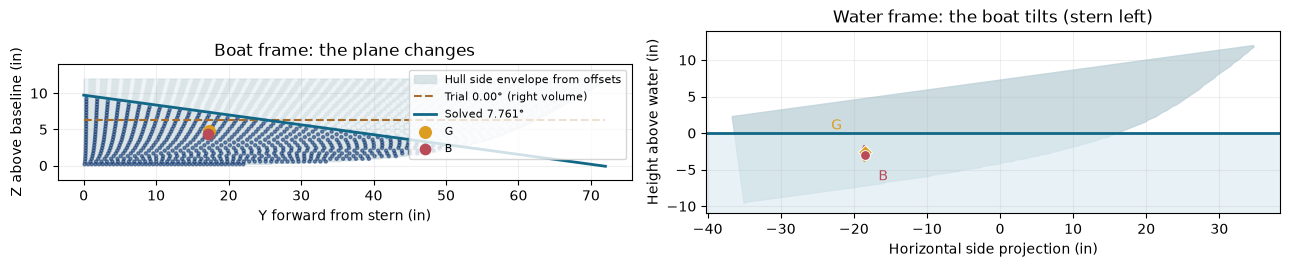

In [7]:
hs_plot_indices = hs_np.flatnonzero(hs_present.any(axis=0))
hs_plot_stations = hs_stations[hs_plot_indices]
hs_y_in = hs_plot_stations/hs_in_to_model_m
hs_z_in = hs_heights/hs_in_to_model_m
hs_bottom = hs_np.array([hs_z_in[hs_present[:,i]][0] for i in hs_plot_indices])
hs_top = hs_np.array([hs_z_in[hs_present[:,i]][-1] for i in hs_plot_indices])
hs_water_solved = (hs_h-hs_k*(hs_plot_stations-hs_mid_y))/hs_in_to_model_m
hs_water_trial = (hs_trial_h-hs_trial_k*(hs_plot_stations-hs_mid_y))/hs_in_to_model_m
hs_fig,hs_ax = hs_plt.subplots(1,2,figsize=(13,3.5))
hs_ax[0].fill_between(hs_y_in,hs_bottom,hs_top,color="#c9d8dc",alpha=.65,label="Hull side envelope from offsets")
hs_pick = hs_np.arange(0,len(hs_grid["x"]),14*2)
hs_ax[0].scatter(hs_grid["y"][hs_pick]/hs_in_to_model_m,
                 (hs_grid["z0"][hs_pick]+hs_grid["dz"][hs_pick]/2)/hs_in_to_model_m,
                 c=hs_solution["wet"]["fraction"][hs_pick],cmap="Blues",vmin=0,vmax=1,s=5,alpha=.5)
hs_ax[0].plot(hs_y_in,hs_water_trial,"--",color="#a86d2a",label=f"Trial {HS_TRIAL_TRIM_DEG:.2f}° (right volume)")
hs_ax[0].plot(hs_y_in,hs_water_solved,color="#126787",lw=2,label=f"Solved {hs_trim_deg:.3f}°")
hs_ax[0].scatter(hs_G[1]/hs_in_to_model_m,hs_G[2]/hs_in_to_model_m,c="#dc9d20",s=70,zorder=5,label="G")
hs_ax[0].scatter(hs_B[1]/hs_in_to_model_m,hs_B[2]/hs_in_to_model_m,c="#b84b57",s=55,zorder=5,label="B")
hs_ax[0].set(xlabel="Y forward from stern (in)",ylabel="Z above baseline (in)",title="Boat frame: the plane changes")
hs_ax[0].legend(fontsize=8,loc="upper right")
def hs_side_to_water(y,z):
    theta = float(hs_np.arctan(hs_k))
    dy = hs_np.asarray(y)-hs_mid_y/hs_in_to_model_m
    dz = hs_np.asarray(z)-hs_h/hs_in_to_model_m
    return dy*hs_np.cos(theta)-dz*hs_np.sin(theta), dy*hs_np.sin(theta)+dz*hs_np.cos(theta)
hs_outline_y = hs_np.r_[hs_y_in,hs_y_in[::-1]]
hs_outline_z = hs_np.r_[hs_bottom,hs_top[::-1]]
hs_horiz,hs_vertical = hs_side_to_water(hs_outline_y,hs_outline_z)
hs_ax[1].fill(hs_horiz,hs_vertical,color="#bfd2d9",alpha=.8)
hs_ax[1].axhspan(min(-12,float(hs_vertical.min())-1),0,color="#dcecf2",alpha=.65)
hs_ax[1].axhline(0,color="#126787",lw=2,label="Horizontal water")
for hs_center,hs_color,hs_label,hs_sign in [(hs_G,"#dc9d20","G",-1),(hs_B,"#b84b57","B",1)]:
    hs_u,hs_v = hs_side_to_water(hs_center[1]/hs_in_to_model_m,hs_center[2]/hs_in_to_model_m)
    hs_ax[1].scatter(hs_u,hs_v,c=hs_color,s=50,marker="D" if hs_label=="G" else "o",edgecolors="white",linewidths=.7,zorder=5)
    hs_ax[1].annotate(hs_label,(hs_u,hs_v),xytext=(-24,16) if hs_label=="G" else (10,-18),textcoords="offset points",color=hs_color)
    hs_ax[1].annotate("",(hs_u,hs_v+hs_sign*2),(hs_u,hs_v),arrowprops={"arrowstyle":"->","color":hs_color,"lw":2})
hs_ax[1].set(xlabel="Horizontal side projection (in)",ylabel="Height above water (in)",title="Water frame: the boat tilts (stern left)")
hs_ax[0].set_ylim(-2,14)
hs_ax[1].set_ylim(-11,14)
for hs_axis in hs_ax:
    hs_axis.set_aspect("equal",adjustable="box");hs_axis.grid(alpha=.2)
hs_fig.tight_layout();hs_plt.show()

## 5. Why that angle and not another angle?

In this sweep, **each trial trim gets its own height adjustment**, so every point
already displaces enough water. We hold heel at its solved value. The plotted
fore/aft alignment residual is what remains to be balanced. Where it crosses
zero, the gravity and buoyancy forces no longer form a fore/aft turning couple.

The convergence graph divides each residual by DBB's own stopping threshold, so
the final point below one means all three tests pass. That is a numerical
stopping test, not an uncertainty estimate for the real boat.

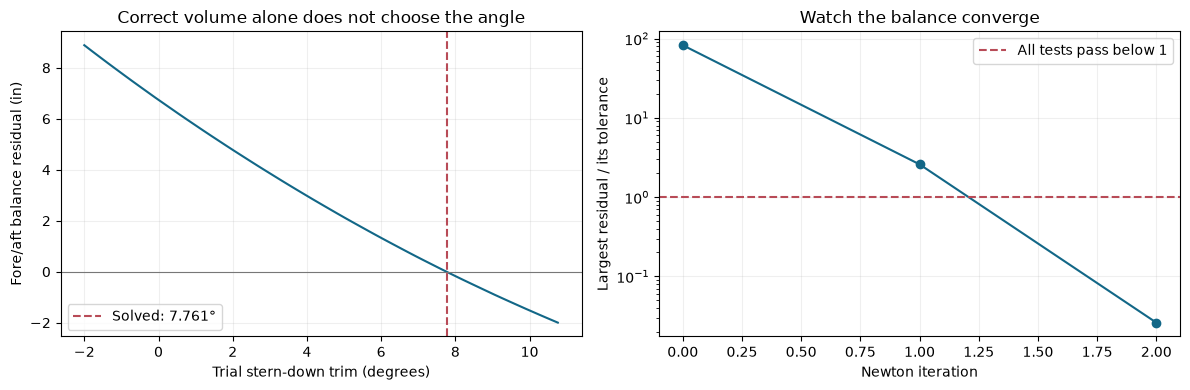

In [6]:
hs_angles = hs_np.linspace(min(-2.,float(hs_trim_deg)-3),max(10.,float(hs_trim_deg)+3),61)
hs_curve = []
for hs_angle in hs_angles:
    hs_slope = float(hs_np.tan(hs_np.deg2rad(hs_angle)))
    hs_height = hs_settle_height(hs_slope,hs_p,hs_target_volume,hs_grid)
    hs_error,hs_wet = hs_residual([hs_height,hs_slope,hs_p],hs_mass_t,hs_G,hs_grid)
    hs_curve.append(hs_error[1]/hs_in_to_model_m)
hs_fig,hs_ax = hs_plt.subplots(1,2,figsize=(12,4))
hs_ax[0].plot(hs_angles,hs_curve,color="#126787")
hs_ax[0].axhline(0,color="#777",lw=.8)
hs_ax[0].axvline(hs_trim_deg,color="#b84b57",ls="--",label=f"Solved: {hs_trim_deg:.3f}°")
hs_ax[0].set(xlabel="Trial stern-down trim (degrees)",ylabel="Fore/aft balance residual (in)",title="Correct volume alone does not choose the angle")
hs_ax[0].legend()
hs_normalized_errors = [max(hs_np.abs(v["residual"])/hs_solution["tolerance"]) for v in hs_solution["history"]]
hs_ax[1].semilogy(range(len(hs_normalized_errors)),hs_np.maximum(hs_normalized_errors,1e-16),"o-",color="#126787")
hs_ax[1].axhline(1,color="#b84b57",ls="--",label="All tests pass below 1")
hs_ax[1].set(xlabel="Newton iteration",ylabel="Largest residual / its tolerance",title="Watch the balance converge")
hs_ax[1].legend()
for hs_axis in hs_ax:hs_axis.grid(alpha=.2)
hs_fig.tight_layout();hs_plt.show()

## 6. Compare the Python walkthrough with original DBB

`outputs/hydrostatics/dbb-walkthrough-reference.json` contains results calculated
by the **unchanged original JavaScript core**, not by this Python code. Source,
CSV and offsets hashes record exactly which inputs were checked. The comparison
runs both loadings. It only asserts agreement when the current input files,
density, scale and original core match that saved reference. Changed inputs are
reported as **reference unavailable**, rather than compared against stale numbers.

The source methods are `offsetsXRange`, `offsetsHalf`, `floatState` and `heelSolve`
in [the original calculation core](dbb-source/core.js).
The [DBB manual](https://shiplab.github.io/dbb/docs/manual.md) explains their scope;
the [scale audit](DBB-SCALING-AUDIT.md) checks the 10× setup.

The offsets approximate the hull, and the cells approximate integration. Openings,
downflooding, waves, speed, appendage/tube buoyancy and large-angle safety criteria
are not added here. A matching implementation is not experimental validation.

In [7]:
hs_reference_path = hs_dir/"dbb-walkthrough-reference.json"
hs_reference = hs_json.loads(hs_reference_path.read_text()) if hs_reference_path.is_file() else None
def hs_sha(path):return hs_hashlib.sha256(path.read_bytes()).hexdigest()
hs_comparison_rows = []
for hs_case_name in ["baseline","updated"]:
    hs_rows,_ = hs_load_weights(hs_case_name)
    hs_result = hs_solve(hs_rows)
    hs_state = hs_result["state"]
    hs_values = {"trim_deg":float(hs_np.rad2deg(hs_np.arctan(hs_state[1]))),
                 "heel_deg":float(hs_np.rad2deg(hs_np.arctan(hs_state[2]))),
                 "stern_waterline_in":float((hs_state[0]+hs_state[1]*hs_mid_y)/hs_in_to_model_m)}
    hs_ref = hs_reference["cases"].get(hs_case_name) if hs_reference else None
    hs_reference_valid = bool(hs_ref and HS_SCALE==10 and HS_WATER_DENSITY_KG_M3==1000
        and hs_sha(hs_dir/hs_files[hs_case_name])==hs_ref["csv_sha256"]
        and hs_sha(hs_dir/"hull-offsets-m.csv")==hs_reference["offsets_sha256"]
        and hs_sha(hs_dir/"dbb-source/core.js")==hs_reference["core_sha256"]
        and hs_sha(hs_geometry_project)==hs_reference["geometry_project_sha256"])
    for hs_key,hs_unit in [("trim_deg","degrees"),("heel_deg","degrees"),("stern_waterline_in","in")]:
        hs_actual = hs_values[hs_key]
        if hs_reference_valid:
            hs_difference = hs_actual-hs_ref[hs_key]
            assert abs(hs_difference)<0.002, f"Python/DBB disagreement: {hs_case_name} {hs_key}: {hs_difference}"
            hs_comparison_rows.append([hs_case_name,hs_key,f"{hs_actual:.8f}",f"{hs_ref[hs_key]:.8f}",f"{hs_difference:+.9f}",hs_unit,"matched"])
        else:
            hs_comparison_rows.append([hs_case_name,hs_key,f"{hs_actual:.8f}","—","—",hs_unit,"reference unavailable: inputs/settings changed or snapshot missing"])
hs_table(["Case","Quantity","Python","Original DBB","Difference","Unit","Check"],hs_comparison_rows)
if HS_POSITION_OVERRIDES_IN:
    print("Above checks use the two saved CSV cases. Your position overrides affect the selected walkthrough case only.")
print("No input CSV or DBB project was modified by this notebook.")

Case,Quantity,Python,Original DBB,Difference,Unit,Check
baseline,trim_deg,0.30257444,0.30257444,+0.000000000,degrees,matched
baseline,heel_deg,0.09905810,0.09905810,-0.000000000,degrees,matched
baseline,stern_waterline_in,6.49089558,6.49089558,+0.000000000,in,matched
updated,trim_deg,7.76113385,7.76113385,+0.000000000,degrees,matched
updated,heel_deg,0.04638485,0.04638485,+0.000000000,degrees,matched
updated,stern_waterline_in,9.72139558,9.72139558,+0.000000000,in,matched


No input CSV or DBB project was modified by this notebook.
